# gputherm on a free cloud GPU

Builds the CPU and CUDA solvers, verifies the GPU against the semi-analytic bioheat solution, then benchmarks CPU vs GPU.

**Colab:** Runtime → Change runtime type → T4 GPU. **Kaggle:** Settings → Accelerator → GPU.

In [1]:
!nvidia-smi
!nvcc --version | tail -2

Wed Oct 28 18:08:48 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
if not os.path.exists('wearable-thermal-cfd'):
    !git clone --depth 1 https://github.com/aminilia/wearable-thermal-cfd
%cd wearable-thermal-cfd/gputherm
!pip -q install -r ../requirements.txt

Cloning into 'wearable-thermal-cfd'...
remote: Enumerating objects: 176, done.
remote: Counting objects: 100% (176/176), done.
remote: Compressing objects: 100% (141/141), done.
remote: Total 176 (delta 23), reused 150 (delta 23), pack-reused 0 (from 0)
Receiving objects: 100% (176/176), 1.51 MiB | 20.60 MiB/s, done.
Resolving deltas: 100% (23/23), done.
/content/wearable-thermal-cfd/gputherm


## Build
`ARCH` is read from the GPU (T4 → `sm_75`, A100 → `sm_80`, L4 → `sm_89`).

In [3]:
cap = !nvidia-smi --query-gpu=compute_cap --format=csv,noheader
arch = 'sm_' + cap[0].strip().replace('.', '')
print(arch)
!make all ARCH={arch}

sm_75
g++ -O3 -march=native -std=c++17 -fopenmp -Wall -Wextra -Iinclude -o bin/gputherm_cpu src/cpu_main.cpp
nvcc -O3 -std=c++17 -arch=sm_75 -lineinfo -Iinclude -o bin/gputherm_cuda src/cuda_main.cu


## 1. Verify
Max cell-centre error vs the semi-analytic 1D bioheat solution on 3 grids; expect ~0.01 mK on the finest grid and observed order 2.00, identical to the CPU.

In [4]:
!python python/verify_column.py --backend cpu
!python python/verify_column.py --backend cuda


[bare]  backend=cpu  T_surface(ref) = 34.662528 C
  refine  cells  max err [mK]  surface err [mK]  order  CG its Picard
       1     89        0.0878            0.0863      -     356      5
       2    178        0.0220            0.0216   2.00     712      5
       4    356        0.0055            0.0054   2.00    1424      5
  3x3 extrusion: lateral spread 1.70e-06 mK, vs 1D 2.44e-06 mK

[device]  backend=cpu  T_surface(ref) = 42.664409 C
  refine  cells  max err [mK]  surface err [mK]  order  CG its Picard
       1     99        0.1981            0.1981      -      99      1
       2    198        0.0495            0.0495   2.00     198      1
       4    396        0.0124            0.0124   2.00     396      1
  3x3 extrusion: lateral spread 3.05e-06 mK, vs 1D 5.73e-06 mK

PASS

[bare]  backend=cuda  T_surface(ref) = 34.662528 C
  refine  cells  max err [mK]  surface err [mK]  order  CG its Picard
       1     89        0.0878            0.0863      -     356      5
       2    

## 2. Benchmark
Time per CG iteration and the effective memory bandwidth it implies (T4 peak ≈ 320 GB/s). Larger N takes longer on the CPU side.

In [5]:
!OMP_NUM_THREADS=$(nproc) python python/bench.py --sizes 32 64 96 128 160

N=  32 cpu   cells=    32,768 iters=   543 solve=   0.199s     0.367 ms/iter  ~  17.1 GB/s  Tmax=328.3172 K
N=  32 cuda  cells=    32,768 iters=   546 solve=   0.045s     0.082 ms/iter  ~  76.7 GB/s  Tmax=328.3172 K
N=  64 cpu   cells=   262,144 iters=  1087 solve=   2.933s     2.698 ms/iter  ~  18.7 GB/s  Tmax=330.9001 K
N=  64 cuda  cells=   262,144 iters=  1094 solve=   0.299s     0.273 ms/iter  ~ 184.2 GB/s  Tmax=330.9001 K
N=  96 cpu   cells=   884,736 iters=  1624 solve=  16.121s     9.926 ms/iter  ~  17.1 GB/s  Tmax=330.8697 K
N=  96 cuda  cells=   884,736 iters=  1625 solve=   1.234s     0.759 ms/iter  ~ 223.7 GB/s  Tmax=330.8697 K
N= 128 cpu   cells= 2,097,152 iters=  2136 solve=  59.523s    27.867 ms/iter  ~  14.4 GB/s  Tmax=331.8346 K
N= 128 cuda  cells= 2,097,152 iters=  2149 solve=   3.528s     1.642 ms/iter  ~ 245.3 GB/s  Tmax=331.8346 K
N= 160 cpu   cells= 4,096,000 iters=  2657 solve= 143.807s    54.124 ms/iter  ~  14.5 GB/s  Tmax=330.7593 K
N= 160 cuda  cells= 4,096,00

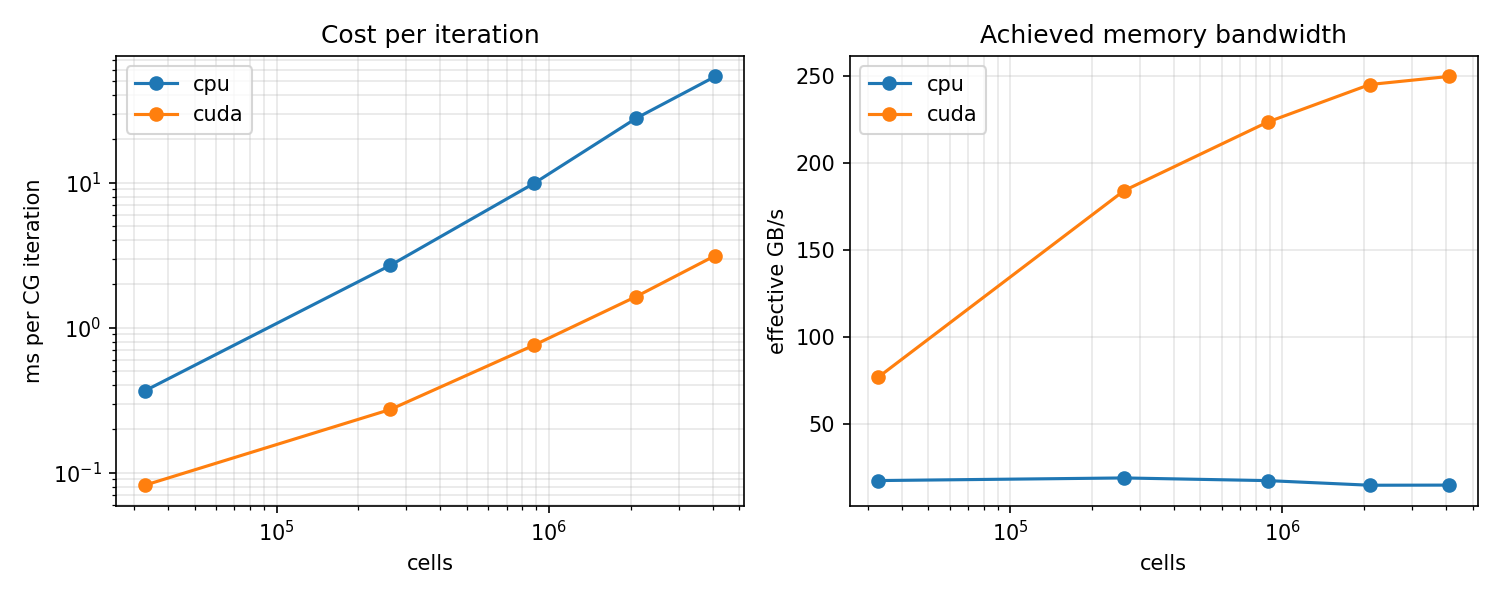

In [6]:
from IPython.display import Image
Image('bench_results.png')

## 3. Profile
Nsight Systems shows the timeline (launch gaps, host round-trips for each dot product). Nsight Compute gives per-kernel memory throughput; free tiers sometimes block its hardware counters (`ERR_NVGPUCTRPERM`). If so, run this cell on a rented GPU instead.

In [7]:
!nsys profile -o v0_timeline --force-overwrite true --stats=true ./bin/gputherm_cuda --bench 128 2>&1 | tail -40

      5.1      188,769,262         12  15,730,771.8  424,861.0   242,470  184,198,804  53,053,702.2  cudaFree                      
      2.2       83,380,679     15,012       5,554.3    4,676.5     3,496      236,727       3,600.9  cudaLaunchKernel              
      0.6       21,995,674      6,438       3,416.5    2,774.0     2,038       46,812       2,257.6  cudaMemsetAsync               
      0.1        2,160,821     15,012         143.9      125.0        89       15,290         227.2  cuKernelGetName               
      0.0        1,186,166         11     107,833.3   77,728.0    62,803      289,250      66,859.6  cudaMalloc                    
      0.0          132,208          1     132,208.0  132,208.0   132,208      132,208           0.0  cuLibraryLoadData             
      0.0            2,695          6         449.2      372.5       272          709         181.2  cuLibraryGetKernel            
      0.0            1,019          1       1,019.0    1,019.0     1,019    

In [8]:
!ncu --kernel-name regex:k_apply --launch-count 1 --section SpeedOfLight --section MemoryWorkloadAnalysis ./bin/gputherm_cuda --bench 128 2>&1 | tail -40

GPU: Tesla T4 (sm_75, 40 SMs)
==PROF== Profiling "k_apply": 0%....50%....100% - 9 passes
{"backend": "cuda", "nx": 128, "ny": 128, "nz": 128, "cells": 2097152, "picard_iters": 5, "picard_dT": 0.000e+00, "cg_iters": 2143, "last_relres": 9.318e-11, "t_assemble_s": 0.458582, "t_solve_s": 8.166895, "t_total_s": 8.662752, "t_per_cg_iter_ms": 3.810964, "T_max": 331.834559572}
==PROF== Disconnected from process 3086
[3086] gputherm_cuda@127.0.0.1
  <unnamed>::k_apply(int, int, int, const double *, const double *, const double *, const double *, const double *, double *) (4, 32, 64)x(32, 4, 2), Context 1, Stream 7, Device 0, CC 7.5
    Section: GPU Speed Of Light Throughput
    ----------------------- ----------- ------------
    Metric Name             Metric Unit Metric Value
    ----------------------- ----------- ------------
    DRAM Frequency                  Ghz         4.94
    SM Frequency                    Mhz       584.97
    Elapsed Cycles                cycle      232,441
    Mem